In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split


print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch: 2.14.0+rocm10.1.0
Device: cuda


In [2]:

colums = ["center", "left", "right", "steering", "throttle", "brake", "speed"]
#lake
files = pd.read_csv("data/driving_log.csv", header=None, names=colums)
#jungle
files = pd.read_csv("data-jungle-new/driving_log.csv", header=None, names=colums)


data = files[["center", "left", "right"]]
y = files[["steering"]]
print(data.head())


                                              center  \
0  /home/peter/Desktop/self-driving-car/data-jung...   
1  /home/peter/Desktop/self-driving-car/data-jung...   
2  /home/peter/Desktop/self-driving-car/data-jung...   
3  /home/peter/Desktop/self-driving-car/data-jung...   
4  /home/peter/Desktop/self-driving-car/data-jung...   

                                                left  \
0  /home/peter/Desktop/self-driving-car/data-jung...   
1  /home/peter/Desktop/self-driving-car/data-jung...   
2  /home/peter/Desktop/self-driving-car/data-jung...   
3  /home/peter/Desktop/self-driving-car/data-jung...   
4  /home/peter/Desktop/self-driving-car/data-jung...   

                                               right  
0  /home/peter/Desktop/self-driving-car/data-jung...  
1  /home/peter/Desktop/self-driving-car/data-jung...  
2  /home/peter/Desktop/self-driving-car/data-jung...  
3  /home/peter/Desktop/self-driving-car/data-jung...  
4  /home/peter/Desktop/self-driving-car/data-jung..

In [3]:
image_dir = Path("data-jungle-new/IMG")

# Convert center, left, right columns into rows
files["frame_id"] = np.arange(len(files))

data = files.melt(
    id_vars=["frame_id", "steering", "throttle", "speed"],
    value_vars=["center", "left", "right"],
    var_name="camera",
    value_name="filename"
)

# Correct steering angles (negative = left)
correction = 0.2

data["steering"] += data["camera"].map({
    "center": 0,
    "left": -correction,
    "right": correction
})

# Load and crop images
images = []

for filename in data["filename"]:
    image_path = image_dir / Path(str(filename).strip()).name

    with Image.open(image_path) as image:
        cropped = image.crop((0, 65, image.width, image.height))
        images.append(np.array(cropped.convert("RGB")))

data["image"] = images


Straight: 34.88%
Left:     32.18%
Right:    32.93%


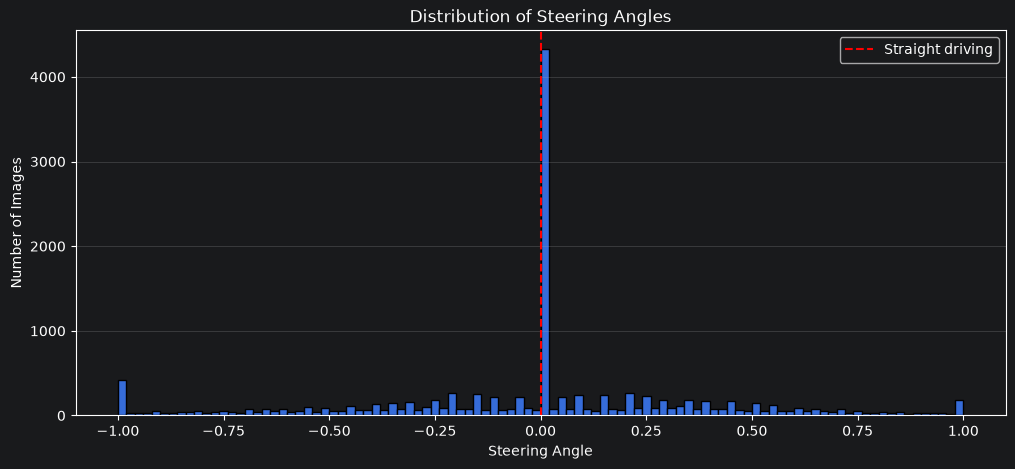

In [4]:
steering = pd.to_numeric(files["steering"], errors="coerce").dropna()

plt.figure(figsize=(12, 5))

plt.hist(steering, bins=100, edgecolor="black")

plt.xlabel("Steering Angle")
plt.ylabel("Number of Images")
plt.title("Distribution of Steering Angles")
plt.axvline(0, color="red", linestyle="--", label="Straight driving")
plt.legend()
plt.grid(axis="y", alpha=0.3)

straight = (steering.abs() < 0.05).sum()
left = (steering <= -0.05).sum()
right = (steering >= 0.05).sum()

total = len(steering)

print(f"Straight: {straight / total * 100:.2f}%")
print(f"Left:     {left / total * 100:.2f}%")
print(f"Right:    {right / total * 100:.2f}%")
plt.show()

data is wayyyy to centered for proper training. this fixes it by keeping only 30% of it

In [5]:
# Split original frame IDs
frame_ids = files["frame_id"].to_numpy()

train_ids, test_ids = train_test_split(
    frame_ids,
    test_size=0.2,
    random_state=42
)

train_data = data[data["frame_id"].isin(train_ids)]
test_data = data[data["frame_id"].isin(test_ids)]

# Undersample BEFORE creating image arrays
straight_indices = np.where(train_data["steering"].to_numpy() == 0)[0]
turning_indices = np.where(train_data["steering"].to_numpy() != 0)[0]

rng = np.random.default_rng(42)

straight_sample = rng.choice(
    straight_indices,
    size=int(len(straight_indices) * 0.70),
    replace=False
)

keep_indices = np.concatenate([
    straight_sample,
    turning_indices
])

rng.shuffle(keep_indices)

train_data = train_data.iloc[keep_indices]

# Create targets
y_train = train_data[["steering", "throttle"]].to_numpy(dtype=np.float32)
y_test = test_data[["steering", "throttle"]].to_numpy(dtype=np.float32)

SPEED_SCALE = 30.19  # Adjust based on the simulator's speed range
speed_train = train_data[["speed"]].to_numpy(dtype=np.float32) / SPEED_SCALE
speed_test = test_data[["speed"]].to_numpy(dtype=np.float32) / SPEED_SCALE

# Create image arrays
X_train = np.stack(train_data["image"].to_numpy())
X_test = np.stack(test_data["image"].to_numpy())

# Convert to NCHW
X_train = X_train.transpose(0, 3, 1, 2)
X_test = X_test.transpose(0, 3, 1, 2)

# Normalize in-place to avoid extra copies
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

X_train /= 255.0
X_test /= 255.0

# Verify no overlap
assert set(train_data["frame_id"]).isdisjoint(
    set(test_data["frame_id"])
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print(f"Straight driving: {(y_train[:, 0] == 0).mean() * 100:.2f}%")

Training images: 30653
Testing images: 7938
Straight driving: 8.29%


In [6]:
import torch.nn as nn

class DrivingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.relu = nn.ReLU()
        self.conv1 = nn.Conv2d(3, 24, 5, 2)
        self.conv2 = nn.Conv2d(24, 36, 5, 2)
        self.conv3 = nn.Conv2d(36, 48, 5, 2)
        self.conv4 = nn.Conv2d(48, 64, 3, 1)
        self.conv5 = nn.Conv2d(64, 64, 3, 1)
        self.fc1 = nn.Linear(10561, 100)
        self.fc2 = nn.Linear(100, 50)
        self.fc3 = nn.Linear(50, 10)
        self.fc4 = nn.Linear(10, 2)


    def forward(self, x, speed):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.relu(self.conv5(x))

        x = torch.flatten(x, start_dim=1)

        # Add speed after CNN feature extraction
        x = torch.cat((x, speed), dim=1)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.fc4(x)

        return x

In [7]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = DrivingCNN().to(device)

# Share memory with existing NumPy arrays
X_train_tensor = torch.from_numpy(X_train)
X_test_tensor = torch.from_numpy(X_test)

y_train_tensor = torch.from_numpy(y_train)
y_test_tensor = torch.from_numpy(y_test)
speed_train_tensor = torch.from_numpy(speed_train)
speed_test_tensor = torch.from_numpy(speed_test)

train_dataset = TensorDataset(
    X_train_tensor,
    speed_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    speed_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

print("Model initialized successfully")

Model initialized successfully


In [8]:
epochs = 500
patience = 25

best_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(epochs):

    # Training
    model.train()
    train_loss = 0

    for images, speeds, targets in train_loader:
        images = images.to(device)
        speeds = speeds.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(images, speeds)

        steering_loss = criterion(predictions[:, 0], targets[:, 0])
        throttle_loss = criterion(predictions[:, 1], targets[:, 1])

        loss = steering_loss + throttle_loss

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # Evaluation
    model.eval()
    test_loss = 0
    test_steering_loss = 0
    test_throttle_loss = 0

    with torch.no_grad():
        for images, speeds, targets in test_loader:
            images = images.to(device)
            speeds = speeds.to(device)
            targets = targets.to(device)

            predictions = model(images, speeds)

            steering_loss = criterion(predictions[:, 0], targets[:, 0])
            throttle_loss = criterion(predictions[:, 1], targets[:, 1])

            loss = steering_loss + throttle_loss

            test_loss += loss.item() * images.size(0)
            test_steering_loss += steering_loss.item() * images.size(0)
            test_throttle_loss += throttle_loss.item() * images.size(0)

    test_loss /= len(test_loader.dataset)
    test_steering_loss /= len(test_loader.dataset)
    test_throttle_loss /= len(test_loader.dataset)

    # Save best model and check early stopping
    if test_loss < best_loss:
        best_loss = test_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), "best_driving_model.pth")

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train: {train_loss:.5f} | "
        f"Steering: {test_steering_loss:.5f} | "
        f"Throttle: {test_throttle_loss:.5f} | "
        f"Patience: {epochs_without_improvement}/{patience}"
    )

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

print(f"Best evaluation loss: {best_loss:.5f}")

MIOpen: Warning [OpenRuntimeLibraryForDevice] CK grouped conv library not found for device gfx1032: libMIOpenCKGroupedConv_gfx1032.so: cannot open shared object file: No such file or directory


Epoch 1/500 | Train: 0.41379 | Steering: 0.18483 | Throttle: 0.19050 | Patience: 0/25
Epoch 2/500 | Train: 0.37902 | Steering: 0.17260 | Throttle: 0.18350 | Patience: 0/25
Epoch 3/500 | Train: 0.33213 | Steering: 0.10611 | Throttle: 0.17656 | Patience: 0/25
Epoch 4/500 | Train: 0.26876 | Steering: 0.09375 | Throttle: 0.16191 | Patience: 0/25
Epoch 5/500 | Train: 0.23672 | Steering: 0.07719 | Throttle: 0.14440 | Patience: 0/25
Epoch 6/500 | Train: 0.21818 | Steering: 0.07446 | Throttle: 0.14381 | Patience: 0/25
Epoch 7/500 | Train: 0.20449 | Steering: 0.07310 | Throttle: 0.13000 | Patience: 0/25
Epoch 8/500 | Train: 0.19393 | Steering: 0.07019 | Throttle: 0.11968 | Patience: 0/25
Epoch 9/500 | Train: 0.18489 | Steering: 0.07050 | Throttle: 0.11375 | Patience: 0/25
Epoch 10/500 | Train: 0.17518 | Steering: 0.06618 | Throttle: 0.11038 | Patience: 0/25
Epoch 11/500 | Train: 0.16629 | Steering: 0.06811 | Throttle: 0.10892 | Patience: 1/25
Epoch 12/500 | Train: 0.15924 | Steering: 0.06630 | 

In [10]:
model.load_state_dict(
    torch.load("best_driving_model.pth", map_location=device)
)

model.eval()

all_predictions = []

with torch.no_grad():
    for images, speeds, targets in test_loader:
        images = images.to(device)
        speeds = speeds.to(device)

        predictions_batch = model(images, speeds)

        # Move results back to CPU immediately
        all_predictions.append(predictions_batch.cpu().numpy())

predictions = np.concatenate(all_predictions, axis=0)